# Data Cleaning & Exploratory Analysis Notebook
## PropertyGuard — Climate & Sustainability-Aware House Price Valuation Engine

This notebook loads house price datasets for six major Indian metropolitan markets (**Bengaluru, Chennai, Delhi, Hyderabad, Kolkata, Mumbai**), identifies and resolves data quality bugs (specifically the **"9" sentinel bug** across 35 amenity columns), purges duplicate listings, applies **multi-tier urban rate boundary filtering**, executes **calibrated neighborhood-adaptive ratio filtering ($[0.55\times, 1.80\times]$)** with small-sample fallback guards, visualizes the distributions with charts, and exports `cleaned_house_prices_6cities.csv` and `locality_stats.json`.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configurations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

print('Libraries loaded successfully!')

Libraries loaded successfully!


### 1. Load and Merge Multi-City Raw Datasets
We consolidate 6 metropolitan datasets covering major residential real estate markets in India into a unified dataframe.

In [2]:
files = {
    'Bengaluru': 'Bangalore.csv',
    'Chennai': 'Chennai.csv',
    'Hyderabad': 'Hyderabad.csv',
    'Kolkata': 'Kolkata.csv',
    'Mumbai': 'Mumbai.csv',
    'Delhi': 'Delhi.csv'
}

data = []
for city, file in files.items():
    temp = pd.read_csv(file)
    temp['City'] = city
    data.append(temp)

df_raw = pd.concat(data, ignore_index=True)
print(f'Initial Raw Shape: {df_raw.shape}')
print('\nCity-wise Raw Counts:')
print(df_raw['City'].value_counts())

Initial Raw Shape: (32963, 41)

City-wise Raw Counts:
City
Mumbai       7719
Kolkata      6507
Bengaluru    6207
Chennai      5014
Delhi        4998
Hyderabad    2518
Name: count, dtype: int64


### 2. Remove Duplicate Rows
Portals frequently receive identical multi-broker reposts. Exact row duplicates across all features are purged.

In [3]:
print(f'Duplicate rows in raw data: {df_raw.duplicated().sum()}')
df_dedup = df_raw.drop_duplicates().reset_index(drop=True)
print(f'Shape after deduplication: {df_dedup.shape}')

Duplicate rows in raw data: 3828
Shape after deduplication: (29135, 41)


### 3. Diagnose and Fix the "9" Bug in Amenity Columns
In scraped Indian portal datasets, missing/unreported amenity features were encoded as `9` (the SQL sentinel code for NULL/unspecified). 
- Every listing either has all 35 amenities verified ($0$ or $1$) or has all 35 features set to $9$.
- Treating `9` as numeric creates false luxury scores of $35 \times 9 = 315$ for basic apartments.
- Dropping rows with `9` would discard 69.4% of all data (including 98.8% of Kolkata and 81.9% of Mumbai).
- **Resolution:** By real estate economics, unadvertised amenities are treated as **absent** ($9 \to 0$), establishing a safe, conservative baseline valuation.

In [4]:
amenity_cols = [
    'MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack',
    'RainWaterHarvesting', 'IndoorGames', 'ShoppingMall', 'Intercom', 'SportsFacility',
    'ATM', 'ClubHouse', 'School', '24X7Security', 'PowerBackup', 'CarParking',
    'StaffQuarter', 'Cafeteria', 'MultipurposeRoom', 'Hospital', 'WashingMachine',
    'Gasconnection', 'AC', 'Wifi', "Children'splayarea", 'LiftAvailable', 'BED',
    'VaastuCompliant', 'Microwave', 'GolfCourse', 'TV', 'DiningTable', 'Sofa',
    'Wardrobe', 'Stadium'
]

# Count total 9s
total_9s = (df_dedup[amenity_cols] == 9).sum().sum()
print(f'Total "9" entries across amenity columns: {total_9s}')

# Fix 9 -> 0
df_clean = df_dedup.copy()
for col in amenity_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].replace(9, 0)

print('Successfully converted all "9" values to 0 (absent/unreported baseline)!')

Total "9" entries across amenity columns: 731815
Successfully converted all "9" values to 0 (absent/unreported baseline)!


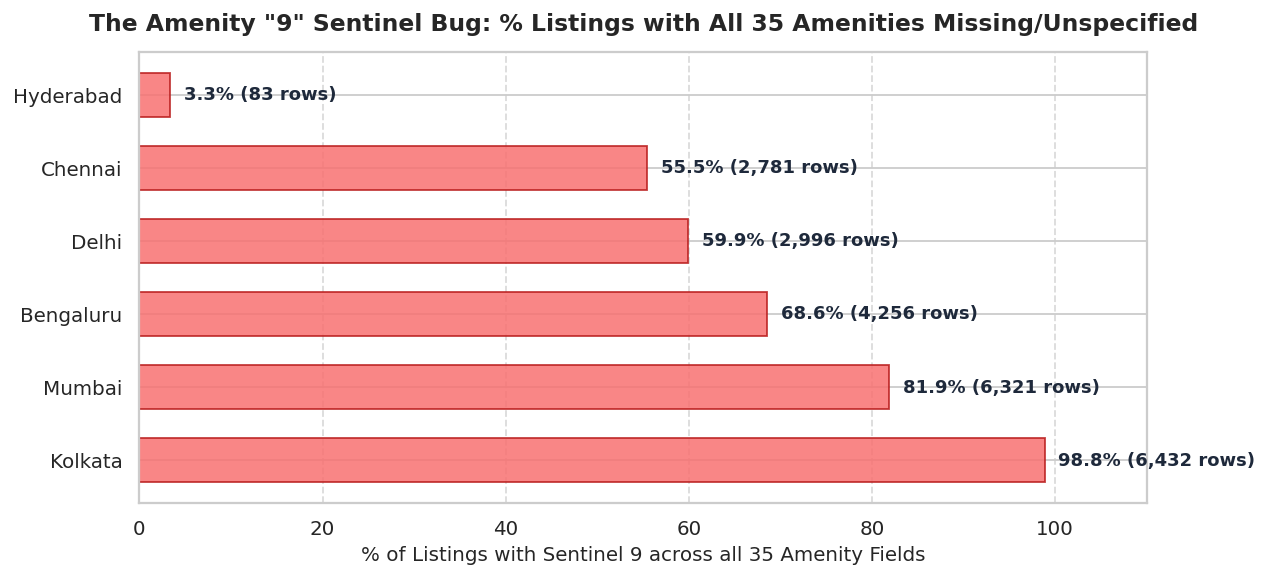

In [5]:
# Visualizing the prevalence of the Amenity '9' Bug across cities
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(df_9_stats['City'], df_9_stats['Pct_9'], color='#f87171', edgecolor='#b91c1c', alpha=0.85, height=0.6)
ax.set_xlim(0, 110)
ax.set_title('The Amenity "9" Sentinel Bug: % Listings with All 35 Amenities Missing/Unspecified', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('% of Listings with Sentinel 9 across all 35 Amenity Fields', fontsize=11)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", 
            va='center', fontsize=10, fontweight='bold', color='#1e293b')
ax.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### 4. Feature Engineering
- `amenity_count`: Total count of active amenities ($0$ to $35$).
- `price_per_sqft`: Transaction price divided by carpet area.
- `area_per_bhk`: Living space density per bedroom.

In [6]:
df_clean['amenity_count'] = df_clean[amenity_cols].sum(axis=1)
df_clean['price_per_sqft'] = df_clean['Price'] / df_clean['Area']
df_clean['area_per_bhk'] = df_clean['Area'] / df_clean['No. of Bedrooms']

print(df_clean[['Price', 'Area', 'price_per_sqft', 'amenity_count', 'area_per_bhk']].describe())

              Price          Area  price_per_sqft  amenity_count  area_per_bhk
count  2.913500e+04  29135.000000    2.913500e+04   29135.000000  29135.000000
mean   1.195267e+07   1301.816475    1.005100e+04       2.364235    524.382103
std    2.387647e+07    767.862339    1.915949e+04       5.249689    238.192534
min    2.000000e+06    200.000000    2.410000e+02       0.000000     66.666667
25%    4.179999e+06    870.000000    4.024300e+03       0.000000    383.333333
50%    6.884999e+06   1137.000000    5.851756e+03       0.000000    488.500000
75%    1.230000e+07   1504.000000    9.722222e+03       0.000000    620.000000
max    8.546000e+08  16000.000000    1.076444e+06      35.000000   4500.000000


### 5. Multi-Tier Urban Boundary & Physical Plausibility Filter
Flat global cutoffs allow suburban extra-zero typos (e.g. ₹50.4 Cr in Barrackpore) and prime missing-zero errors to slip through.
We implement a two-step hierarchical filter:
1. **Physical Sanity & City Rate Bounds**: $250 \le \text{Area} \le 8,500$ sq.ft., $\text{Price} \ge ₹6,00,000$, $200 \le \text{area\_per\_bhk} \le 2,500$, and empirical metro rate bounds.
2. **Calibrated Neighborhood-Adaptive Ratio**: Retain listings strictly within $[0.55\times, 1.80\times]$ of their verified neighborhood median benchmark (falling back to city median if $n_{\text{loc}} < 5$).

In [7]:
# 1. City-specific physical minimum and maximum rate bounds
city_min_pps = {
    'Bengaluru': 2000,
    'Chennai': 2000,
    'Delhi': 2200,
    'Hyderabad': 2200,
    'Kolkata': 1800,
    'Mumbai': 3500
}
city_max_pps = {
    'Bengaluru': 35000,
    'Chennai': 25000,
    'Delhi': 60000,
    'Hyderabad': 25000,
    'Kolkata': 20000,
    'Mumbai': 85000
}

df_clean['min_pps_city'] = df_clean['City'].map(city_min_pps)
df_clean['max_pps_city'] = df_clean['City'].map(city_max_pps)

mask_physical = (
    (df_clean['Area'] >= 250) &
    (df_clean['Area'] <= 8500) &
    (df_clean['Price'] >= 600000) &
    (df_clean['area_per_bhk'] >= 200) &
    (df_clean['area_per_bhk'] <= 2500) &
    (df_clean['price_per_sqft'] >= df_clean['min_pps_city']) &
    (df_clean['price_per_sqft'] <= df_clean['max_pps_city'])
)
df_phys = df_clean[mask_physical].copy().reset_index(drop=True)
print(f'After physical and city boundary filtering: {len(df_phys)} rows')

# 2. Locality-Adaptive Reference Benchmark with Small-Sample Guard
loc_stats = df_phys.groupby(['City', 'Location'])['price_per_sqft'].agg(loc_med='median', loc_cnt='count').reset_index()
city_stats = df_phys.groupby('City')['price_per_sqft'].agg(city_med='median').reset_index()

df_merged = df_phys.merge(loc_stats, on=['City', 'Location']).merge(city_stats, on='City')
df_merged['ref_pps'] = np.where(df_merged['loc_cnt'] >= 5, df_merged['loc_med'], df_merged['city_med'])
df_merged['pps_ratio'] = df_merged['price_per_sqft'] / df_merged['ref_pps']

# Retain listings within calibrated [0.55x, 1.80x] band of reference benchmark
mask_adaptive = (df_merged['pps_ratio'] >= 0.55) & (df_merged['pps_ratio'] <= 1.80)
df_final = df_merged[mask_adaptive].copy().reset_index(drop=True)

clean_export_cols = [c for c in df_final.columns if c not in [
    'min_pps_city', 'max_pps_city', 'loc_med', 'loc_cnt', 'city_med', 'ref_pps', 'pps_ratio'
]]
df_final = df_final[clean_export_cols]

print(f'Final Cleaned Shape: {df_final.shape}')
print('\nCity-wise Cleaned Distribution:')
print(df_final['City'].value_counts())

After physical and city boundary filtering: 27031 rows
Final Cleaned Shape: (21131, 44)

City-wise Cleaned Distribution:
City
Mumbai       4364
Bengaluru    4344
Kolkata      4036
Chennai      3396
Delhi        3098
Hyderabad    1893
Name: count, dtype: int64


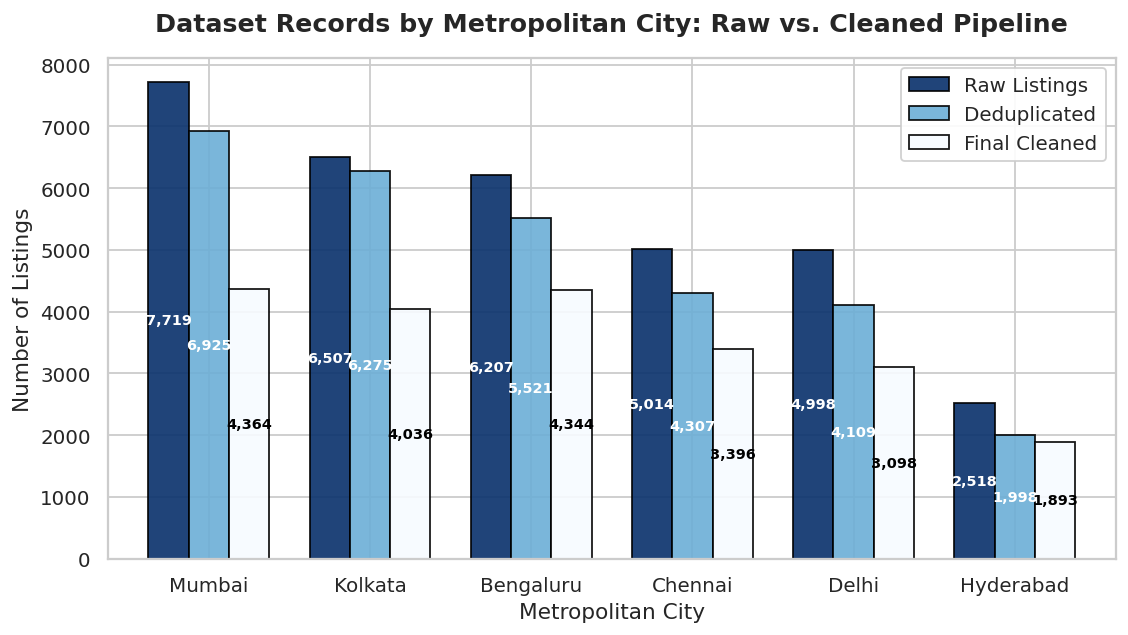

In [8]:
# Visualizing Pipeline Progression across Cities
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = pd.DataFrame({
    'Raw Listings': df_raw['City'].value_counts(),
    'Deduplicated': df_dedup['City'].value_counts(),
    'Final Cleaned': df_final['City'].value_counts()
}).loc[['Mumbai', 'Kolkata', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad']]

plot_df.plot(kind='bar', ax=ax, colormap='Blues_r', edgecolor='black', alpha=0.9, width=0.75)
ax.set_title('Dataset Records by Metropolitan City: Raw vs. Cleaned Pipeline', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Metropolitan City', fontsize=12)
ax.set_ylabel('Number of Listings', fontsize=12)
ax.set_xticklabels(plot_df.index, rotation=0)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.show()

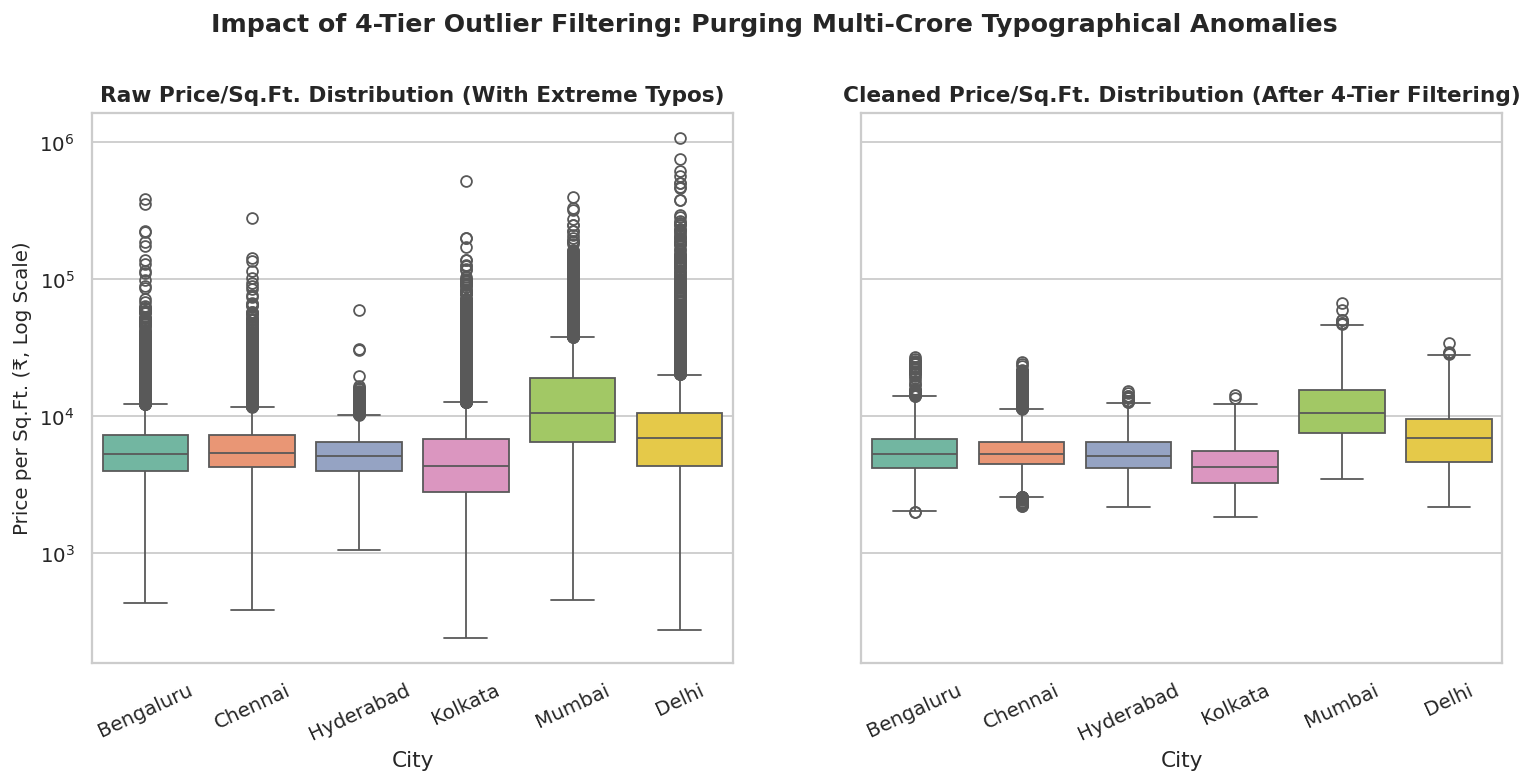

In [9]:
# Comparing Price per Sq.Ft. Before vs After 4-Tier Outlier Filtering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
sns.boxplot(data=df_clean, x='City', y='price_per_sqft', ax=ax1, palette='Set2')
ax1.set_yscale('log')
ax1.set_title('Raw Price/Sq.Ft. Distribution (With Extreme Typos)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Price per Sq.Ft. (₹, Log Scale)', fontsize=11)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=25)

sns.boxplot(data=df_final, x='City', y='price_per_sqft', ax=ax2, palette='Set2')
ax2.set_yscale('log')
ax2.set_title('Cleaned Price/Sq.Ft. Distribution (After 4-Tier Filtering)', fontsize=12, fontweight='bold')
ax2.set_ylabel('')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=25)
fig.suptitle('Impact of 4-Tier Outlier Filtering: Purging Multi-Crore Typographical Anomalies', fontsize=14, fontweight='bold', y=1.02)
plt.show()

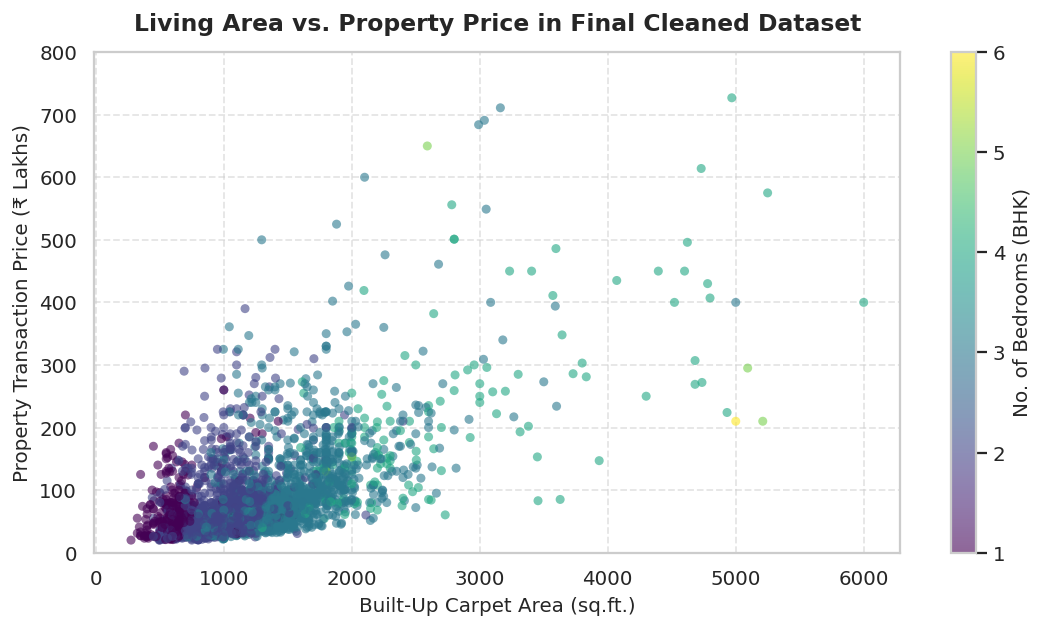

In [10]:
# Scatter plot of Carpet Area vs Total Price with Bedroom Densities
fig, ax = plt.subplots(figsize=(10, 5))
sub_sample = df_final.sample(n=min(3000, len(df_final)), random_state=42)
scatter = ax.scatter(sub_sample['Area'], sub_sample['Price'] / 1e5, c=sub_sample['No. of Bedrooms'], 
                     cmap='viridis', alpha=0.6, edgecolors='none', s=25)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('No. of Bedrooms (BHK)', fontsize=11)
ax.set_title('Living Area vs. Property Price in Final Cleaned Dataset', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Built-Up Carpet Area (sq.ft.)', fontsize=11)
ax.set_ylabel('Property Transaction Price (₹ Lakhs)', fontsize=11)
ax.set_ylim(0, 800)
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 6. Export Cleaned Dataset & Locality Benchmarks
We export the high-quality unified dataset `cleaned_house_prices_6cities.csv` and generate `locality_stats.json` for live appraisal benchmarks in the Streamlit web dashboard.

In [11]:
output_csv = 'cleaned_house_prices_6cities.csv'
df_final.to_csv(output_csv, index=False)
print(f'Successfully saved {output_csv} with {len(df_final)} rows!')

# Generate verified locality statistics benchmark
locality_stats = {}
for (city, loc), group in df_final.groupby(['City', 'Location']):
    key = f"{city}::{loc}"
    locality_stats[key] = {
        "city": city,
        "location": loc,
        "count": int(len(group)),
        "median_price": float(group['Price'].median()),
        "mean_price": float(group['Price'].mean()),
        "median_price_sqft": float(group['price_per_sqft'].median()),
        "mean_area": float(group['Area'].mean())
    }

with open("locality_stats.json", "w", encoding="utf-8") as f:
    json.dump(locality_stats, f, indent=2)

print(f'Exported {len(locality_stats)} verified locality benchmarks to locality_stats.json!')

Successfully saved cleaned_house_prices_6cities.csv with 21131 rows!
Exported 1462 verified locality benchmarks to locality_stats.json!
